In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

# Parte 1 — Imports e Configuração

In [2]:
# Configurações globais
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'Arial'
pd.set_option('display.float_format', '{:,.0f}'.format)
pd.set_option('display.max_columns', 20)

# Constantes
ARQUIVO_DADOS = 'IFData_-_09_2025.csv'
COR_PRINCIPAL = '#1B3F7A'
COR_DESTAQUE  = '#C0395A'

print('✓ Ambiente configurado com sucesso!')
print(f'  Pandas:     {pd.__version__}')
print(f'  NumPy:      {np.__version__}')
print(f'  Matplotlib: {plt.matplotlib.__version__}')

✓ Ambiente configurado com sucesso!
  Pandas:     2.2.3
  NumPy:      2.1.3
  Matplotlib: 3.10.0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Parte 2 — Carregamento dos Dados

In [25]:
df_raw = pd.read_csv('/content/drive/MyDrive/IFData_-_09_2025.csv', sep=';', encoding='utf-8-sig')

In [27]:
print(df_raw)

                               Instituição  Código  TCB   SR   TD  TC  \
0                                     ITAU  10,069   b1   S1    C   2   
1                                       BB  49,906   b1   S1    C   1   
2                  CAIXA ECONÔMICA FEDERAL  51,626   b1   S1    C   1   
3                                 BRADESCO  10,045   b1   S1    C   2   
4                                SANTANDER  30,379   b1   S1    C   3   
...                                    ...     ...  ...  ...  ...  ..   
1494                           1 - Público     NaN  NaN  NaN  NaN NaN   
1495                  2 - Privado Nacional     NaN  NaN  NaN  NaN NaN   
1496                  2 - Privado Nacional     NaN  NaN  NaN  NaN NaN   
1497  3 - Privado com Controle Estrangeiro     NaN  NaN  NaN  NaN NaN   
1498  3 - Privado com Controle Estrangeiro     NaN  NaN  NaN  NaN NaN   

         Cidade   UF     Data    Ativo Total Carteira de Crédito  \
0     SAO PAULO   SP  09/2025  2.689.456.820       1.11

In [28]:
# Ler o CSV do IF.data
print(f'Linhas: {df_raw.shape[0]:,}')
print(f'Colunas: {df_raw.shape[1]}')
print()
print('Colunas disponíveis:')
for col in df_raw.columns:
    print(f'  - {col}')

Linhas: 1,499
Colunas: 19

Colunas disponíveis:
  - Instituição
  - Código
  - TCB
  - SR
  - TD
  - TC
  - Cidade
  - UF
  - Data
  - Ativo Total
  - Carteira de Crédito
  - Títulos e Valores Mobiliários
  - Passivo Exigível
  - Captações
  - Patrimônio Líquido
  - Lucro Líquido
  - Número de Agências
  - Número de Postos de Atendimento
  - Unnamed: 18


In [29]:
df_raw.head(10) # Visualizar as primeiras linhas

,Instituição,Código,TCB,SR,TD,TC,Cidade,UF,Data,Ativo Total,Carteira de Crédito,Títulos e Valores Mobiliários,Passivo Exigível,Captações,Patrimônio Líquido,Lucro Líquido,Número de Agências,Número de Postos de Atendimento,Unnamed: 18
0,ITAU,"10,069",b1,S1,C,2,SAO PAULO,SP,09/2025,2.689.456.820,1.119.067.920,659.840.783,2.474.135.126,2.105.016.675,215.321.694,11.961.715,1.727,1.285,NaN
1,BB,"49,906",b1,S1,C,1,BRASILIA,DF,09/2025,2.538.606.264,1.103.570.994,659.102.445,2.359.524.419,2.015.972.025,179.081.845,3.100.155,3.995,398,NaN
2,CAIXA ECONÔMICA FEDERAL,"51,626",b1,S1,C,1,BRASILIA,DF,09/2025,2.193.995.134,1.258.965.203,433.520.123,2.081.316.463,1.911.742.569,112.678.670,3.510.204,3.247,1.023,NaN
3,BRADESCO,"10,045",b1,S1,C,2,OSASCO,SP,09/2025,1.826.149.502,842.463.316,299.048.054,1.646.311.796,1.430.201.829,179.837.706,6.384.369,2.157,808,NaN
4,SANTANDER,"30,379",b1,S1,C,3,SAO PAULO,SP,09/2025,1.276.426.350,528.719.260,271.940.975,1.181.383.526,984.251.575,95.042.824,4.106.122,2.136,1.789,NaN
5,BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E ...,"33,657,248",b4,S2,C,1,RIO DE JANEIRO,RJ,09/2025,905.220.074,337.101.530,163.600.304,736.690.922,596.672.518,168.529.152,3.897.466,5,0,NaN
6,BTG PACTUAL,"49,944",b1,S1,C,2,RIO DE JANEIRO,RJ,09/2025,665.445.894,168.426.944,205.485.096,597.330.797,460.048.347,68.115.098,4.337.377,66,0,NaN
7,XP,"52,120",b1,S2,C,2,RIO DE JANEIRO,RJ,09/2025,307.101.659,33.329.722,109.000.669,294.990.308,219.008.553,12.111.351,205.279,11,0,NaN
8,SAFRA,"10,083",b1,S2,C,2,SAO PAULO,SP,09/2025,271.094.929,132.708.479,69.307.857,252.005.262,207.723.576,19.089.667,1.128.996,188,3,NaN
9,NUBANK,"52,058",n1,S2,C,3,SAO PAULO,SP,09/2025,219.449.385,61.661.647,65.169.820,207.181.651,186.790.022,12.267.733,2.198.336,4,0,NaN


In [30]:
df_raw.info() # Informações sobre tipos e nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1499 entries, 0 to 1498
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Instituição                      1499 non-null   object 
 1   Código                           1459 non-null   float64
 2   TCB                              1459 non-null   object 
 3   SR                               1335 non-null   object 
 4   TD                               1458 non-null   object 
 5   TC                               1459 non-null   float64
 6   Cidade                           1459 non-null   object 
 7   UF                               1459 non-null   object 
 8   Data                             1459 non-null   object 
 9   Ativo Total                      1495 non-null   object 
 10  Carteira de Crédito              1495 non-null   object 
 11  Títulos e Valores Mobiliários    1495 non-null   object 
 12  Passivo Exigível    

# Parte 3 --- Limpeza e preparação de dados

In [32]:
# Trabalhar em uma cópia
df = df_raw.copy()

# Remover linhas sem TCB (totalizadoras no final do arquivo)
df = df[df['TCB'].notna() & (df['TCB'] != '')]

# Remover linhas com Ativo Total = NI ou vazio
df = df[~df['Ativo Total'].isin(['NI', '', None])]
df = df[df['Ativo Total'].notna()]

print(f'Após filtros: {len(df):,} registros')

Após filtros: 1,419 registros


In [33]:
# Converter colunas financeiras para número
colunas_financeiras = [
    'Ativo Total', 'Carteira de Crédito', 'Títulos e Valores Mobiliários',
    'Passivo Exigível', 'Captações', 'Patrimônio Líquido', 'Lucro Líquido'
]

for col in colunas_financeiras:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace('.', '', regex=False)
            .str.replace(',', '.', regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Converter agências e postos
for col in ['Número de Agências', 'Número de Postos de Atendimento']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# Remover duplicatas
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print(f'Base limpa: {len(df):,} registros')
print(f'Colunas numéricas OK: {df[colunas_financeiras].dtypes.tolist()}')

Base limpa: 1,419 registros
Colunas numéricas OK: [dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64')]


In [48]:
# Criar colunas calculadas
df['ROE'] = df['Lucro Líquido'] / df['Patrimônio Líquido'].replace(0, np.nan)
df['Indice_Credito_Ativo'] = df['Carteira de Crédito'] / df['Ativo Total'].replace(0, np.nan)
df['Digital'] = (df['Número de Agências'] == 0).map({True: 'Digital', False: 'Tradicional'})

# Decodificar tipo de controle
tc_map = {'1': 'Público', '2': 'Privado Nacional', '3': 'Privado Estrangeiro'}
df['Tipo_Controle'] = df['TC'].astype(str).map(tc_map)

print('Colunas calculadas criadas:')
print('  - ROE (Retorno sobre Patrimônio)')
print('  - Indice_Credito_Ativo')
print('  - Digital (Digital/Tradicional)')
print('  - Tipo_Controle (legível)')

Colunas calculadas criadas:
  - ROE (Retorno sobre Patrimônio)
  - Indice_Credito_Ativo
  - Digital (Digital/Tradicional)
  - Tipo_Controle (legível)


# Exercicio 1 - Verificação de Qualidade

In [68]:
# EXERCÍCIO 1 — Escreva suas respostas aqui

# 1. ROE nulos
# Quantidade de valores nulos (NaN) na coluna ROE
roe_nulos = df['ROE'].isna().sum()
print(f"Quantidade de ROE nulos: {roe_nulos}")

# 2. % de nulos em Lucro Líquido
# Percentual de valores nulos (NaN) na coluna Lucro Líquido
pct_nulos_lucro = df['Lucro Líquido'].isna().mean() * 100
print(f"% de nulos em Lucro Líquido: {pct_nulos_lucro:.2f}%")

# 3. Valores únicos de SR
# Usando unique() para listar os valores sem tentar somá-los
valores_unicos_sr = df['SR'].dropna().unique()
print(f"Valores únicos de SR: {valores_unicos_sr}")

Quantidade de ROE nulos: 0
% de nulos em Lucro Líquido: 0.00%
Valores únicos de SR: ['S1' 'S2' 'S3' 'S4' 'S5']


In [64]:
df.head(10)

,Instituição,Código,TCB,SR,TD,TC,Cidade,UF,Data,Ativo Total,...,Captações,Patrimônio Líquido,Lucro Líquido,Número de Agências,Número de Postos de Atendimento,Unnamed: 18,ROE,Indice_Credito_Ativo,Digital,Tipo_Controle
0,ITAU,"10,069",b1,S1,C,2,SAO PAULO,SP,09/2025,2689456820,...,2105016675,215321694,11961715,1,1,NaN,0,0,Tradicional,NaN
1,BB,"49,906",b1,S1,C,1,BRASILIA,DF,09/2025,2538606264,...,2015972025,179081845,3100155,3,398,NaN,0,0,Tradicional,NaN
2,CAIXA ECONÔMICA FEDERAL,"51,626",b1,S1,C,1,BRASILIA,DF,09/2025,2193995134,...,1911742569,112678670,3510204,3,1,NaN,0,1,Tradicional,NaN
3,BRADESCO,"10,045",b1,S1,C,2,OSASCO,SP,09/2025,1826149502,...,1430201829,179837706,6384369,2,808,NaN,0,0,Tradicional,NaN
4,SANTANDER,"30,379",b1,S1,C,3,SAO PAULO,SP,09/2025,1276426350,...,984251575,95042824,4106122,2,1,NaN,0,0,Tradicional,NaN
5,BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E ...,"33,657,248",b4,S2,C,1,RIO DE JANEIRO,RJ,09/2025,905220074,...,596672518,168529152,3897466,5,0,NaN,0,0,Tradicional,NaN
6,BTG PACTUAL,"49,944",b1,S1,C,2,RIO DE JANEIRO,RJ,09/2025,665445894,...,460048347,68115098,4337377,66,0,NaN,0,0,Tradicional,NaN
7,XP,"52,120",b1,S2,C,2,RIO DE JANEIRO,RJ,09/2025,307101659,...,219008553,12111351,205279,11,0,NaN,0,0,Tradicional,NaN
8,SAFRA,"10,083",b1,S2,C,2,SAO PAULO,SP,09/2025,271094929,...,207723576,19089667,1128996,188,3,NaN,0,0,Tradicional,NaN
9,NUBANK,"52,058",n1,S2,C,3,SAO PAULO,SP,09/2025,219449385,...,186790022,12267733,2198336,4,0,NaN,0,0,Tradicional,NaN


# Parte 4 - Analise exploratoria de dados EDA

In [69]:
# Estatísticas descritivas das variáveis numéricas principais
cols_analise = ['Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido', 'Lucro Líquido', 'ROE']
df[cols_analise].describe().round(2)

,Ativo Total,Carteira de Crédito,Patrimônio Líquido,Lucro Líquido,ROE
count,"1,419","1,419","1,419","1,419","1,419"
mean,"12,648,994","5,279,066","1,166,588","42,385",-0
std,"132,947,494","60,662,768","10,909,860","439,283",1
min,375,0,"-41,472","-252,606",-36
25%,"17,592",184,"8,748",10,0
50%,"257,657","49,921","46,385",632,0
75%,"1,468,441","557,000","216,915","5,722",0
max,"2,689,456,820","1,258,965,203","215,321,694","11,961,715",4


In [73]:
# Distribuição por tipo de controle
print('=== Distribuição por Tipo de Controle ===')
print(df['Tipo_Controle'].value_counts())
print()

# Distribuição por segmento
print('=== Distribuição por Segmento (SR) ===')
print(df['SR'].value_counts().sort_index())
print()

# Bancos digitais vs tradicionais
print('=== Digital vs Tradicional ===')
print(df['Digital'].value_counts())

=== Distribuição por Tipo de Controle ===
Series([], Name: count, dtype: int64)

=== Distribuição por Segmento (SR) ===
SR
S1     11
S2     14
S3     71
S4    382
S5    828
Name: count, dtype: int64

=== Digital vs Tradicional ===
Digital
Digital        767
Tradicional    652
Name: count, dtype: int64


In [74]:
# Resumo por segmento — o coração da EDA
resumo_segmento = df.groupby('SR').agg(
    qtd=('Instituição', 'count'),
    ativo_soma=('Ativo Total', 'sum'),
    ativo_medio=('Ativo Total', 'mean'),
    credito_soma=('Carteira de Crédito', 'sum'),
    roe_medio=('ROE', 'mean'),
    lucro_soma=('Lucro Líquido', 'sum')
).round(2)

resumo_segmento['pct_ativo'] = (resumo_segmento['ativo_soma'] / resumo_segmento['ativo_soma'].sum() * 100).round(1)

print(resumo_segmento.to_string())

    qtd   ativo_soma   ativo_medio  credito_soma  roe_medio  lucro_soma  pct_ativo
SR                                                                                
S1   11  11420629420 1,038,239,038    5037217362         -0    34368024         64
S2   14   2811793783   200,842,413     891168607          0    12936601         16
S3   71   2195713757    30,925,546     922615546          0     6751033         12
S4  382    901420249     2,359,739     389222314         -0     3434666          5
S5  828    463986554       560,370     248358598          0     1933594          3


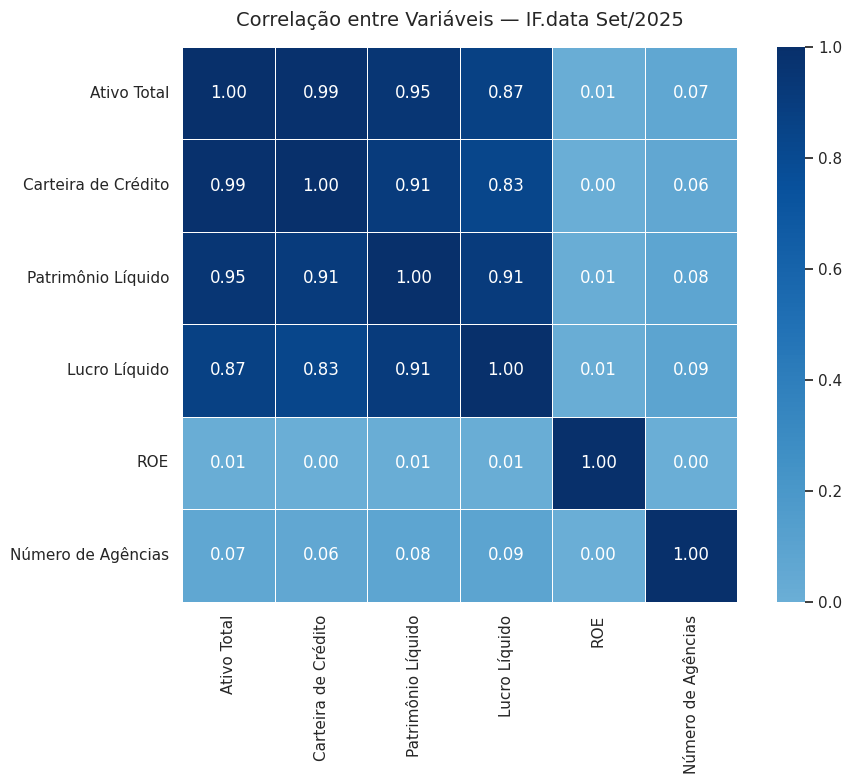

✓ Gráfico salvo: correlacao_ifdata.png


In [72]:
# Matriz de correlação
corr_cols = ['Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido',
             'Lucro Líquido', 'ROE', 'Número de Agências']
corr = df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Correlação entre Variáveis — IF.data Set/2025', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('correlacao_ifdata.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ Gráfico salvo: correlacao_ifdata.png')

# Exercicio 2 - Analise exploratoria

In [87]:
# EXERCÍCIO 2 — Escreva suas respostas aqui

# 1. Mediana vs média do Ativo Total
mediana_ativo = df['Ativo Total'].median()
media_ativo = df['Ativo Total'].mean()

print("=== 1. Mediana vs Média do Ativo Total ===")
print(f"Mediana do Ativo Total: R$ {mediana_ativo:,.2f}")
print(f"Média do Ativo Total:   R$ {media_ativo:,.2f}")
print("Como a média é muito maior que a mediana, temos uma distribuição fortemente distorcida para a direita (presença de grandes bancos).")
print()

# 2. Instituições com ROE > 15%
# Selecionando e exibindo formatado localmente para podermos ver as casas decimais do ROE
df_roe_15 = df[df['ROE'] > 0.15][['Instituição', 'Patrimônio Líquido', 'Lucro Líquido', 'ROE']]

print("=== 2. Instituições com ROE > 15% ===")
print(f"Total de instituições: {len(df_roe_15)}")
# Usamos o style do pandas para formatar apenas nesta exibição as casas decimais
display(df_roe_15.head(10).style.format({'Patrimônio Líquido': 'R$ {:,.2f}', 'Lucro Líquido': 'R$ {:,.2f}', 'ROE': '{:.2%}'}))
print()

# 3. Correlação agências x ativo
correlacao_ag_ativo = df['Número de Agências'].corr(df['Ativo Total'])

print("=== 3. Correlação entre Número de Agências e Ativo Total ===")
print(f"Coeficiente de Correlação de Pearson: {correlacao_ag_ativo:.4f}")
print()

# 4. Resumo por Tipo_Controle
# Correção do mapeamento de Tipo de Controle garantindo a conversão para inteiro
tc_map_numeric = {1: 'Público', 2: 'Privado Nacional', 3: 'Privado Estrangeiro'}
df['Tipo_Controle'] = df['TC'].map(tc_map_numeric)

resumo_controle = df.groupby('Tipo_Controle').agg(
    Qtd_Instituicoes=('Instituição', 'count'),
    Ativo_Total_Soma=('Ativo Total', 'sum'),
    ROE_Medio=('ROE', 'mean')
)

print("=== 4. Resumo por Tipo de Controle ===")
display(resumo_controle.style.format({'Ativo_Total_Soma': 'R$ {:,.2f}', 'ROE_Medio': '{:.2%}'}))

=== 1. Mediana vs Média do Ativo Total ===
Mediana do Ativo Total: R$ 257,657.00
Média do Ativo Total:   R$ 12,648,993.82
Como a média é muito maior que a mediana, temos uma distribuição fortemente distorcida para a direita (presença de grandes bancos).

=== 2. Instituições com ROE > 15% ===
Total de instituições: 66


,Instituição,Patrimônio Líquido,Lucro Líquido,ROE
9,NUBANK,"R$ 12,267,733.00","R$ 2,198,336.00",17.92%
19,NU PAGAMENTOS S.A. - INSTITUIÇÃO DE PAGAMENTO,"R$ 19,332,954.00","R$ 2,902,783.00",15.01%
49,"STONE SOCIEDADE DE CREDITO, FINANCIAMENTO E INVESTIMENTO S.A.","R$ 194,789.00","R$ 38,794.00",19.92%
118,ALELO INSTITUICAO DE PAGAMENTO SA,"R$ 1,191,558.00","R$ 185,924.00",15.60%
147,CONFEDERAÇÃO NACIONAL DAS COOPERATIVAS CENTRAIS DE CRÉDITO E ECONOMIA FAMILIAR E SOLIDÁRIA - CRESOL CONFEDERAÇÃO,"R$ 210,746.00","R$ 60,889.00",28.89%
240,MONEY PLUS,"R$ 357,942.00","R$ 110,299.00",30.81%
267,BANCO AFINZ S.A. - BANCO MÚLTIPLO,"R$ 195,286.00","R$ 37,279.00",19.09%
316,EBANX INSTITUICAO DE PAGAMENTOS LTDA.,"R$ 82,915.00","R$ 29,881.00",36.04%
327,AFINZ INSTITUIÇÃO DE PAGAMENTO S.A.,"R$ 120,344.00","R$ 51,352.00",42.67%
385,IUGU INSTITUIÇÃO DE PAGAMENTO S.A.,"R$ -41,472.00","R$ -82,045.00",197.83%



=== 3. Correlação entre Número de Agências e Ativo Total ===
Coeficiente de Correlação de Pearson: 0.0708

=== 4. Resumo por Tipo de Controle ===


,Qtd_Instituicoes,Ativo_Total_Soma,ROE_Medio
Tipo_Controle,,,
Privado Estrangeiro,175,"R$ 3,022,481,106.00",2.43%
Privado Nacional,1214,"R$ 8,776,628,286.00",-3.27%
Público,30,"R$ 6,149,812,836.00",1.31%


In [78]:
df.head(10)

,Instituição,Código,TCB,SR,TD,TC,Cidade,UF,Data,Ativo Total,...,Captações,Patrimônio Líquido,Lucro Líquido,Número de Agências,Número de Postos de Atendimento,Unnamed: 18,ROE,Indice_Credito_Ativo,Digital,Tipo_Controle
0,ITAU,"10,069",b1,S1,C,2,SAO PAULO,SP,09/2025,2689456820,...,2105016675,215321694,11961715,1,1,NaN,0,0,Tradicional,NaN
1,BB,"49,906",b1,S1,C,1,BRASILIA,DF,09/2025,2538606264,...,2015972025,179081845,3100155,3,398,NaN,0,0,Tradicional,NaN
2,CAIXA ECONÔMICA FEDERAL,"51,626",b1,S1,C,1,BRASILIA,DF,09/2025,2193995134,...,1911742569,112678670,3510204,3,1,NaN,0,1,Tradicional,NaN
3,BRADESCO,"10,045",b1,S1,C,2,OSASCO,SP,09/2025,1826149502,...,1430201829,179837706,6384369,2,808,NaN,0,0,Tradicional,NaN
4,SANTANDER,"30,379",b1,S1,C,3,SAO PAULO,SP,09/2025,1276426350,...,984251575,95042824,4106122,2,1,NaN,0,0,Tradicional,NaN
5,BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E ...,"33,657,248",b4,S2,C,1,RIO DE JANEIRO,RJ,09/2025,905220074,...,596672518,168529152,3897466,5,0,NaN,0,0,Tradicional,NaN
6,BTG PACTUAL,"49,944",b1,S1,C,2,RIO DE JANEIRO,RJ,09/2025,665445894,...,460048347,68115098,4337377,66,0,NaN,0,0,Tradicional,NaN
7,XP,"52,120",b1,S2,C,2,RIO DE JANEIRO,RJ,09/2025,307101659,...,219008553,12111351,205279,11,0,NaN,0,0,Tradicional,NaN
8,SAFRA,"10,083",b1,S2,C,2,SAO PAULO,SP,09/2025,271094929,...,207723576,19089667,1128996,188,3,NaN,0,0,Tradicional,NaN
9,NUBANK,"52,058",n1,S2,C,3,SAO PAULO,SP,09/2025,219449385,...,186790022,12267733,2198336,4,0,NaN,0,0,Tradicional,NaN


# Parte 5 - Visualização com matplotlib e Seaborn

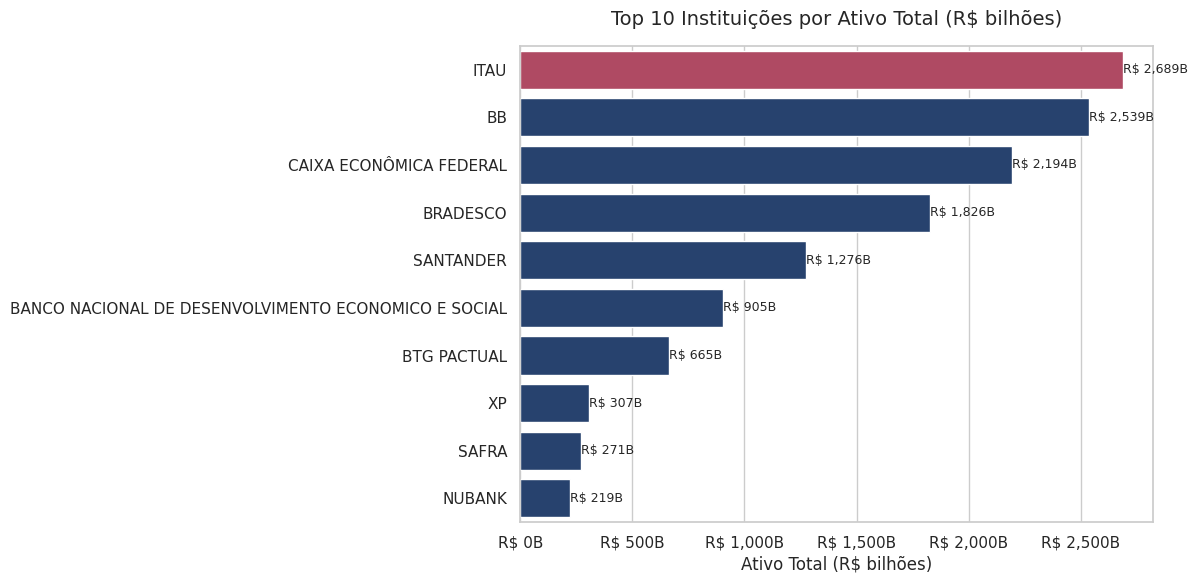

✓ top10_ativo.png


In [80]:
# Gráfico 1: Top 10 por Ativo Total
top10 = df.nlargest(10, 'Ativo Total')[['Instituição', 'SR', 'Ativo Total', 'ROE']].copy()
top10['Ativo_Bi'] = top10['Ativo Total'] / 1_000_000  # converter para R$ bilhões

fig, ax = plt.subplots(figsize=(12, 6))
barras = sns.barplot(
    data=top10, y='Instituição', x='Ativo_Bi',
    palette=[COR_DESTAQUE if i == 0 else COR_PRINCIPAL for i in range(len(top10))],
    ax=ax
)
ax.set_title('Top 10 Instituições por Ativo Total (R$ bilhões)', fontsize=14, pad=15)
ax.set_xlabel('Ativo Total (R$ bilhões)')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}B'))
for bar in ax.patches:
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'R$ {bar.get_width():,.0f}B', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('top10_ativo.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ top10_ativo.png')

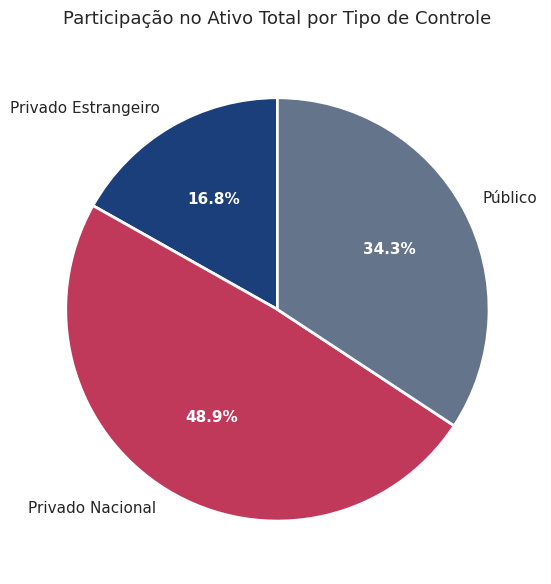

✓ ativo_controle.png


In [83]:
# Gráfico 2: Distribuição de ativo por tipo de controle
ativo_controle = df.groupby('Tipo_Controle')['Ativo Total'].sum().reset_index()
ativo_controle['pct'] = ativo_controle['Ativo Total'] / ativo_controle['Ativo Total'].sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
cores = [COR_PRINCIPAL, COR_DESTAQUE, '#64748B']
wedges, texts, autotexts = ax.pie(
    ativo_controle['Ativo Total'],
    labels=ativo_controle['Tipo_Controle'],
    autopct='%1.1f%%',
    colors=cores,
    startangle=90,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'}
)
for text in autotexts:
    text.set_fontsize(11)
    text.set_color('white')
    text.set_fontweight('bold')
ax.set_title('Participação no Ativo Total por Tipo de Controle', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig('ativo_controle.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ ativo_controle.png')

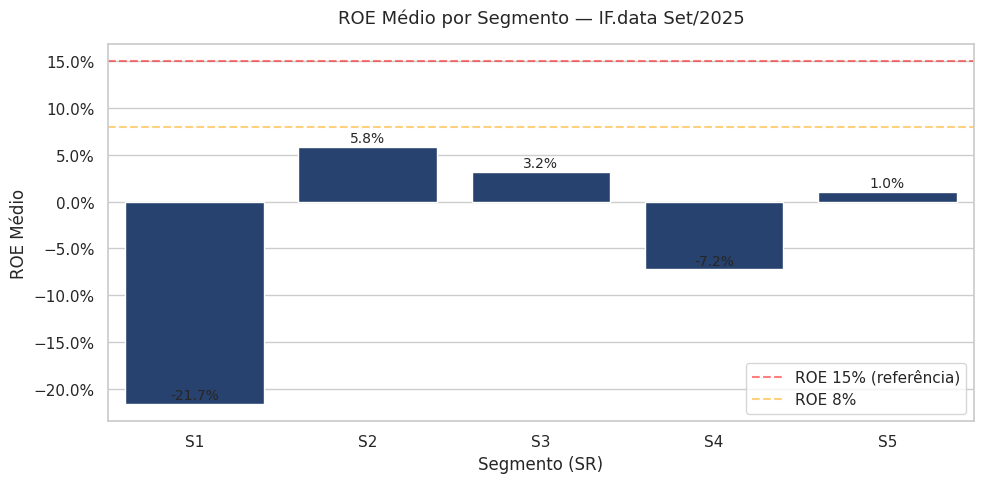

✓ roe_segmento.png


In [84]:
# Gráfico 3: ROE por segmento
roe_seg = df.groupby('SR')['ROE'].mean().reset_index().sort_values('SR')
roe_seg = roe_seg[roe_seg['SR'].isin(['S1','S2','S3','S4','S5'])]

fig, ax = plt.subplots(figsize=(10, 5))
cores_roe = [COR_DESTAQUE if r > 0.15 else COR_PRINCIPAL for r in roe_seg['ROE']]
sns.barplot(data=roe_seg, x='SR', y='ROE', palette=cores_roe, ax=ax)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
ax.axhline(0.15, color='red', linestyle='--', alpha=0.5, label='ROE 15% (referência)')
ax.axhline(0.08, color='orange', linestyle='--', alpha=0.5, label='ROE 8%')
ax.set_title('ROE Médio por Segmento — IF.data Set/2025', fontsize=13, pad=15)
ax.set_xlabel('Segmento (SR)')
ax.set_ylabel('ROE Médio')
ax.legend()

# Rótulos nas barras
for bar in ax.patches:
    h = bar.get_height()
    if not np.isnan(h):
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                f'{h:.1%}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('roe_segmento.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ roe_segmento.png')

# Exercicio 3 - Exportação dos resultados

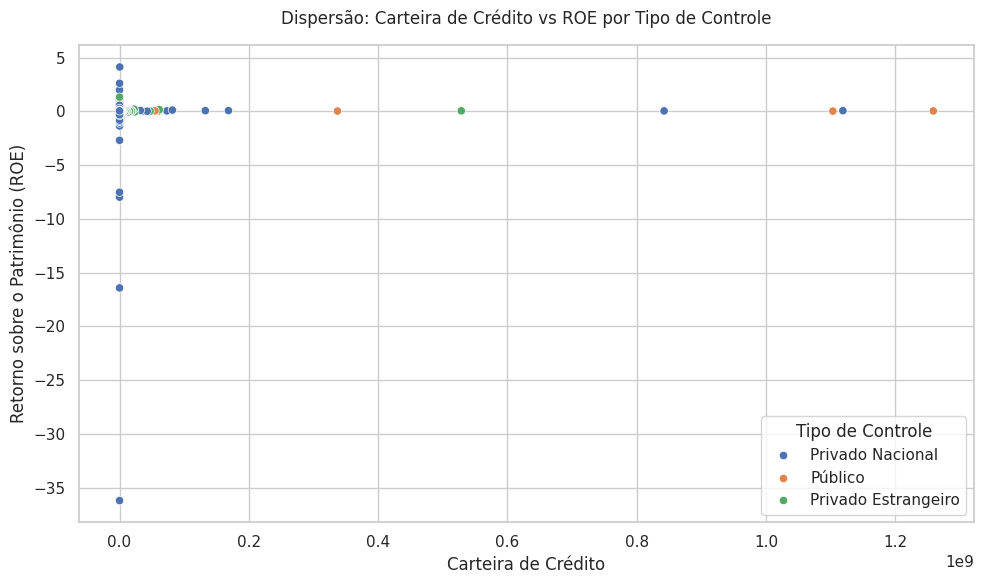

In [92]:
# EXERCÍCIO 3 — Crie o gráfico de dispersão aqui

# Dica: use sns.scatterplot() com hue='Tipo_Controle'
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Carteira de Crédito',
    y='ROE',
    hue='Tipo_Controle',
    palette='deep',
)

plt.xlabel('Carteira de Crédito')
plt.ylabel('Retorno sobre o Patrimônio (ROE)')
plt.title('Dispersão: Carteira de Crédito vs ROE por Tipo de Controle', fontsize=12, pad=15)
plt.legend(title='Tipo de Controle')
plt.tight_layout()
plt.show()

In [86]:
df.head()

,Instituição,Código,TCB,SR,TD,TC,Cidade,UF,Data,Ativo Total,...,Captações,Patrimônio Líquido,Lucro Líquido,Número de Agências,Número de Postos de Atendimento,Unnamed: 18,ROE,Indice_Credito_Ativo,Digital,Tipo_Controle
0,ITAU,"10,069",b1,S1,C,2,SAO PAULO,SP,09/2025,2689456820,...,2105016675,215321694,11961715,1,1,NaN,0,0,Tradicional,Privado Nacional
1,BB,"49,906",b1,S1,C,1,BRASILIA,DF,09/2025,2538606264,...,2015972025,179081845,3100155,3,398,NaN,0,0,Tradicional,Público
2,CAIXA ECONÔMICA FEDERAL,"51,626",b1,S1,C,1,BRASILIA,DF,09/2025,2193995134,...,1911742569,112678670,3510204,3,1,NaN,0,1,Tradicional,Público
3,BRADESCO,"10,045",b1,S1,C,2,OSASCO,SP,09/2025,1826149502,...,1430201829,179837706,6384369,2,808,NaN,0,0,Tradicional,Privado Nacional
4,SANTANDER,"30,379",b1,S1,C,3,SAO PAULO,SP,09/2025,1276426350,...,984251575,95042824,4106122,2,1,NaN,0,0,Tradicional,Privado Estrangeiro


# Parte 6 - Exportação dos Resultados

In [93]:
# Preparar tabelas para exportação
top10_export = df.nlargest(10, 'Ativo Total')[[
    'Instituição', 'SR', 'Tipo_Controle', 'UF',
    'Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido',
    'Lucro Líquido', 'ROE', 'Número de Agências', 'Digital'
]].copy()

top10_export['ROE'] = top10_export['ROE'].apply(lambda x: f'{x:.1%}' if pd.notna(x) else 'N/A')

# Classificar ROE
def classificar_roe(roe_str):
    if roe_str == 'N/A': return 'N/A'
    roe = float(roe_str.strip('%')) / 100
    if roe > 0.15: return 'Excelente'
    if roe > 0.08: return 'Bom'
    if roe > 0: return 'Fraco'
    return 'Prejuízo'

top10_export['Classificação ROE'] = top10_export['ROE'].apply(classificar_roe)

print('Tabela pronta para exportação:')
print(top10_export[['Instituição', 'SR', 'ROE', 'Classificação ROE']].to_string())

Tabela pronta para exportação:
                                            Instituição  SR    ROE Classificação ROE
0                                                  ITAU  S1   5.6%             Fraco
1                                                    BB  S1   1.7%             Fraco
2                               CAIXA ECONÔMICA FEDERAL  S1   3.1%             Fraco
3                                              BRADESCO  S1   3.6%             Fraco
4                                             SANTANDER  S1   4.3%             Fraco
5  BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E SOCIAL  S2   2.3%             Fraco
6                                           BTG PACTUAL  S1   6.4%             Fraco
7                                                    XP  S2   1.7%             Fraco
8                                                 SAFRA  S2   5.9%             Fraco
9                                                NUBANK  S2  17.9%         Excelente


In [94]:
# Exportar para Excel com múltiplas abas
with pd.ExcelWriter('M6_Analise_IFdata.xlsx', engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Base_Limpa', index=False)
    top10_export.to_excel(writer, sheet_name='Top10_Ativo', index=False)
    resumo_segmento.to_excel(writer, sheet_name='Resumo_Segmento')

# Exportar base limpa em CSV
df.to_csv('ifdata_limpo.csv', index=False, encoding='utf-8-sig')

print('✓ Arquivos exportados:')
print('  - M6_Analise_IFdata.xlsx (3 abas)')
print('  - ifdata_limpo.csv')
print('  - top10_ativo.png')
print('  - ativo_controle.png')
print('  - roe_segmento.png')
print('  - correlacao_ifdata.png')

✓ Arquivos exportados:
  - M6_Analise_IFdata.xlsx (3 abas)
  - ifdata_limpo.csv
  - top10_ativo.png
  - ativo_controle.png
  - roe_segmento.png
  - correlacao_ifdata.png


# Parte 7 - Automação Relatorio por Segmento

In [95]:
def analisar_segmento(df, segmento, salvar=True):
    """Gera análise completa para um segmento do IF.data.

    Args:
        df: DataFrame limpo com os dados do IF.data
        segmento: código do segmento (ex: 'S1', 'S2')
        salvar: se True, salva o gráfico em PNG

    Returns:
        dict: estatísticas do segmento
    """
    dados = df[df['SR'] == segmento].copy()

    if len(dados) == 0:
        return None

    # Estatísticas
    stats = {
        'segmento': segmento,
        'qtd_instituicoes': len(dados),
        'ativo_soma': dados['Ativo Total'].sum(),
        'ativo_medio': dados['Ativo Total'].mean(),
        'roe_medio': dados['ROE'].mean(),
        'qtd_digital': (dados['Digital'] == 'Digital').sum(),
        'pct_digital': (dados['Digital'] == 'Digital').mean()
    }

    if salvar and len(dados) >= 3:
        # Gráfico das top instituições do segmento
        top_seg = dados.nlargest(min(10, len(dados)), 'Ativo Total')
        fig, ax = plt.subplots(figsize=(10, max(4, len(top_seg) * 0.5)))
        sns.barplot(data=top_seg, y='Instituição', x='Ativo Total',
                    color=COR_PRINCIPAL, ax=ax)
        ax.set_title(
            f'Segmento {segmento} — {stats["qtd_instituicoes"]} instituições\n'
            f'Ativo total: R$ {stats["ativo_soma"]:,.0f} mil',
            fontsize=12
        )
        ax.set_xlabel('Ativo Total (R$ mil)')
        ax.set_ylabel('')
        plt.tight_layout()
        plt.savefig(f'segmento_{segmento}.png', dpi=150, bbox_inches='tight')
        plt.close()

    return stats


# Executar para todos os segmentos
segmentos = ['S1', 'S2', 'S3', 'S4', 'S5']
resultados = []

for seg in segmentos:
    stats = analisar_segmento(df, seg, salvar=True)
    if stats:
        resultados.append(stats)
        print(f'✓ Segmento {seg}: {stats["qtd_instituicoes"]} instituições | '
              f'ROE médio: {stats["roe_medio"]:.1%} | '
              f'Digitais: {stats["pct_digital"]:.0%}')

# Salvar resultado consolidado
df_resultados = pd.DataFrame(resultados)
df_resultados.to_excel('relatorio_segmentos.xlsx', index=False)
print('\n✓ relatorio_segmentos.xlsx gerado!')

✓ Segmento S1: 11 instituições | ROE médio: -21.7% | Digitais: 0%


✓ Segmento S2: 14 instituições | ROE médio: 5.8% | Digitais: 0%


✓ Segmento S3: 71 instituições | ROE médio: 3.2% | Digitais: 18%


✓ Segmento S4: 382 instituições | ROE médio: -7.2% | Digitais: 34%


✓ Segmento S5: 828 instituições | ROE médio: 1.0% | Digitais: 75%

✓ relatorio_segmentos.xlsx gerado!


# Exercicio 4 - Automação

In [98]:
# EXERCÍCIO 4 — Crie a função analisar_controle aqui

def analisar_controle(df, tipo_controle, salvar=True):
    """Gera análise para um tipo de controle.

    Args:
        df: DataFrame limpo
        tipo_controle: 'Público', 'Privado Nacional' ou 'Privado Estrangeiro'
        salvar: se True, salva o gráfico

    Returns:
        dict: estatísticas
    """
    # seu código aqui
    analisar_controle = df[df['Tipo_Controle'] == tipo_controle].copy()
    pass


# Chamar em loop para os 3 tipos
# seu código aqui




# Parte 8 - Boas praticas e Checklist final

In [96]:
# Checklist de qualidade do notebook
checklist = [
    ('✓', 'Imports todos na Parte 1'),
    ('✓', 'Constantes em MAIÚSCULO no início'),
    ('✓', 'Base original nunca modificada (df_raw preservado)'),
    ('✓', 'Cada etapa em célula separada com título Markdown'),
    ('✓', 'Funções com docstring explicando parâmetros e retorno'),
    ('✓', 'Gráficos salvos com plt.savefig() antes do plt.show()'),
    ('✓', 'Excel exportado com múltiplas abas organizadas'),
    ('✓', 'Células executadas em ordem (sem erros)'),
    ('✓', 'Markdown com a conclusão da análise no final'),
]

print('CHECKLIST DE QUALIDADE:')
for status, item in checklist:
    print(f'  [{status}] {item}')

CHECKLIST DE QUALIDADE:
  [✓] Imports todos na Parte 1
  [✓] Constantes em MAIÚSCULO no início
  [✓] Base original nunca modificada (df_raw preservado)
  [✓] Cada etapa em célula separada com título Markdown
  [✓] Funções com docstring explicando parâmetros e retorno
  [✓] Gráficos salvos com plt.savefig() antes do plt.show()
  [✓] Excel exportado com múltiplas abas organizadas
  [✓] Células executadas em ordem (sem erros)
  [✓] Markdown com a conclusão da análise no final
